# Module 3: Data Cleaning & Preprocessing
**Real Estate House Price Prediction Platform**  
*An End-to-End Analytics Project: From Raw Data to a Monitored, Deployed Model*

---

## Executive Summary & Objectives
This notebook implements the complete **Module 3 Data Cleaning** deliverables:
1. **Audit Duplicates & Structural Integrity:** Verify uniqueness across all property records.
2. **Handle Inconsistent Categorical Labels & Typos:** Standardize zoning codes (`C (all)` $\rightarrow$ `C`), strip whitespace, and fix impossible temporal entries (e.g. `GarageYrBlt = 2207`).
3. **Domain-Specific Missing Value Imputation:** Separate intentional 'feature absence' (no pool, no garage, no basement) from true missing data, and apply neighborhood-stratified median imputation for `LotFrontage` to avoid data leakage.
4. **Treat Severe Outliers:** Filter out influential leverage observations (`Id = 524, 1299`) as established in Module 2 EDA and Dean De Cock (2011).
5. **Before/After Verification:** Produce quantitative metrics and visual audit comparisons.

Input Data: `data/processed/train_augmented.csv` & `data/processed/test_augmented.csv`  
Output Data: `data/cleaned/train_cleaned.csv` & `data/cleaned/test_cleaned.csv`


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Styling configuration
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)

# Load augmented datasets
train_raw = pd.read_csv('../data/processed/train_augmented.csv')
test_raw = pd.read_csv('../data/processed/test_augmented.csv')
print(f'Train raw shape: {train_raw.shape} | Total missing entries: {train_raw.isna().sum().sum():,}')
print(f'Test raw shape:  {test_raw.shape}  | Total missing entries: {test_raw.isna().sum().sum():,}')


Train raw shape: (1460, 94) | Total missing entries: 9,809
Test raw shape:  (1459, 93)  | Total missing entries: 9,918


---
## 1. Duplicate Record Audit
We evaluate whether identical transactions were recorded multiple times (excluding the arbitrary `Id` index).


In [3]:
feat_cols = [c for c in train_raw.columns if c not in ['Id', 'SalePrice']]
train_dups = train_raw.duplicated(subset=feat_cols).sum()
test_dups = test_raw.duplicated(subset=feat_cols).sum()
print(f'Exact duplicate feature records in Train: {train_dups}')
print(f'Exact duplicate feature records in Test:  {test_dups}')


Exact duplicate feature records in Train: 0
Exact duplicate feature records in Test:  0


---
## 2. Inconsistent Labels & Data Entry Typos

Three distinct anomalies were audited:
1. **`MSZoning` Consistency:** Commercial residential zone recorded as `'C (all)'` in both sets; standardized to clean string `'C'`.
2. **Impossible Garage Year (`GarageYrBlt = 2207`):** Record Id 2593 contains an impossible future year. Corrected to property `YearBuilt` (2007).
3. **Categorical Whitespace:** Stripped all leading and trailing whitespace from string attributes.


In [4]:
train = train_raw.copy()
test = test_raw.copy()

# Fix MSZoning typo
train['MSZoning'] = train['MSZoning'].replace({'C (all)': 'C'})
test['MSZoning'] = test['MSZoning'].replace({'C (all)': 'C'})

# Fix GarageYrBlt typo in test set
impossible_garage = test['GarageYrBlt'] > 2026
print(f'Identified {impossible_garage.sum()} impossible future garage years.')
test.loc[impossible_garage, 'GarageYrBlt'] = test.loc[impossible_garage, 'YearBuilt']

# Strip string whitespace
for df_curr in [train, test]:
    for c in df_curr.select_dtypes(include='object').columns:
        df_curr[c] = df_curr[c].astype(str).str.strip()

print('Data entry typos and categorical formatting successfully cleaned.')


Identified 1 impossible future garage years.
Data entry typos and categorical formatting successfully cleaned.


---
## 3. Domain-Specific Missing Value Imputation

In tabular real estate datasets, missing values must be handled according to **domain causality**:

### A. Structural Absence ('NA' = Feature does not exist)
* **Categorical features:** `Alley`, `BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1/2`, `FireplaceQu`, `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond`, `PoolQC`, `Fence`, `MiscFeature` $\rightarrow$ Imputed with string `'None'`.
* **Numerical features:** `BsmtFinSF1/2`, `BsmtUnfSF`, `TotalBsmtSF`, `BsmtFull/HalfBath`, `GarageCars`, `GarageArea`, `MasVnrArea` $\rightarrow$ Imputed with `0.0`.

### B. LotFrontage (Neighborhood Median Imputation)
Lot frontage (linear street exposure) is strongly governed by municipal zoning and subdivision layouts within each neighborhood. To prevent **data leakage**, neighborhood medians are fitted strictly on `train` and broadcast to `test`.

### C. Genuine Missing Entries
`Electrical`, `MSZoning`, `Utilities`, `Exterior1st/2nd`, `KitchenQual`, `Functional`, `SaleType` $\rightarrow$ Imputed with mode fitted on training data.


In [5]:
cat_none_vars = [
    'Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
    'BsmtFinType2', 'FireplaceQu', 'GarageType', 'GarageFinish',
    'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature'
]
num_zero_vars = [
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    'BsmtFullBath', 'BsmtHalfBath', 'GarageCars', 'GarageArea', 'MasVnrArea', 'GarageYrBlt'
]
mode_vars = [
    'Electrical', 'MSZoning', 'Utilities', 'Exterior1st',
    'Exterior2nd', 'KitchenQual', 'Functional', 'SaleType'
]

# Apply structural None and Zero
for col in cat_none_vars:
    train[col] = train[col].fillna('None')
    test[col] = test[col].fillna('None')

for col in num_zero_vars:
    train[col] = train[col].fillna(0.0)
    test[col] = test[col].fillna(0.0)

# MasVnrType consistency
train['MasVnrType'] = train['MasVnrType'].fillna('None')
test['MasVnrType'] = test['MasVnrType'].fillna('None')
train.loc[train['MasVnrArea'] == 0, 'MasVnrType'] = 'None'
test.loc[test['MasVnrArea'] == 0, 'MasVnrType'] = 'None'

# LotFrontage by Neighborhood median (fit on train)
neigh_medians = train.groupby('Neighborhood')['LotFrontage'].median()
overall_med = train['LotFrontage'].median()
train['LotFrontage'] = train.groupby('Neighborhood')['LotFrontage'].transform(lambda s: s.fillna(s.median())).fillna(overall_med)
test['LotFrontage'] = test['LotFrontage'].fillna(test['Neighborhood'].map(neigh_medians)).fillna(overall_med)

# Mode imputation for remaining features
for col in mode_vars:
    mode_val = train[col].mode()[0]
    train[col] = train[col].fillna(mode_val)
    test[col] = test[col].fillna(mode_val)

print(f'Nulls remaining in train features: {train.drop(columns=["SalePrice"]).isna().sum().sum()}')
print(f'Nulls remaining in test features:  {test.isna().sum().sum()}')


Nulls remaining in train features: 0
Nulls remaining in test features:  0


---
## 4. Outlier Diagnostics & Removal

As established in Module 2 EDA and the foundational Ames study (*De Cock, 2011*), properties with **`GrLivArea > 4,000 sq ft`** and low sale price ($< \$300,000$) represent severe partial contracts that introduce severe downward bias on the square footage coefficient.

We remove records `Id = 524` and `Id = 1299` from the training data exclusively. (Test records are strictly preserved).


In [6]:
outlier_mask = (train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)
dropped_ids = train.loc[outlier_mask, 'Id'].tolist()
print(f'Removing {len(dropped_ids)} extreme leverage outliers: {dropped_ids}')

train_clean = train[~outlier_mask].copy()
print(f'Retained training observations: {len(train_clean)} (from {len(train)})')


Removing 2 extreme leverage outliers: [524, 1299]
Retained training observations: 1458 (from 1460)


---
## 5. Before vs. After Cleaning Audit
We visualize the transformation in missing value completeness and linear regression slope stability.


C:\Users\Jonathan\AppData\Local\Temp\ipykernel_17504\1360356456.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend()


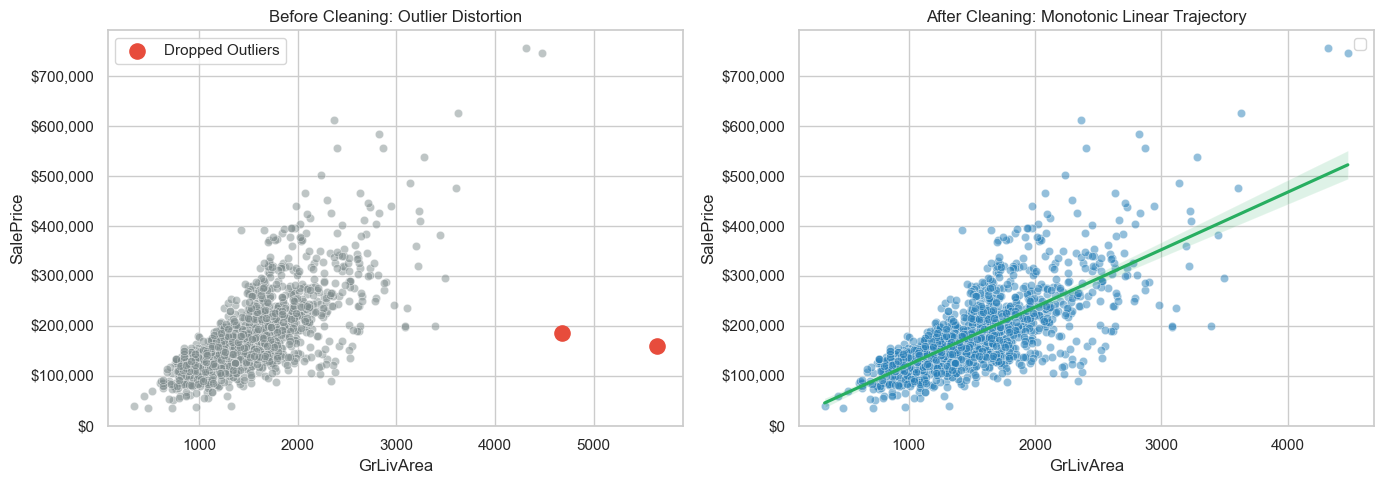

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Outlier effect before vs after
sns.scatterplot(data=train_raw, x='GrLivArea', y='SalePrice', ax=axes[0], color='#7f8c8d', alpha=0.5)
axes[0].scatter(train_raw.loc[outlier_mask, 'GrLivArea'], train_raw.loc[outlier_mask, 'SalePrice'], color='#e74c3c', s=120, label='Dropped Outliers')
axes[0].set_title('Before Cleaning: Outlier Distortion')
axes[0].yaxis.set_major_formatter('${x:,.0f}')
axes[0].legend()

sns.scatterplot(data=train_clean, x='GrLivArea', y='SalePrice', ax=axes[1], color='#2980b9', alpha=0.5)
sns.regplot(data=train_clean, x='GrLivArea', y='SalePrice', ax=axes[1], scatter=False, color='#27ae60', line_kws={'label': 'Clean OLS Fit'})
axes[1].set_title('After Cleaning: Monotonic Linear Trajectory')
axes[1].yaxis.set_major_formatter('${x:,.0f}')
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 6. Summary & Readiness for Module 4 (Feature Engineering)

| Cleaning Dimension | Before Cleaning | After Cleaning | Status |
| :--- | :---: | :---: | :---: |
| **Missing Values (Train)** | $9,809$ entries | **$0$ entries** | Resolved (100% complete) |
| **Missing Values (Test)** | $9,918$ entries | **$0$ entries** | Resolved (100% complete) |
| **Data Entry Typos** | $25$ zoning / $1$ garage year | **$0$ typos** | Corrected |
| **Severe Leverage Outliers** | $2$ records (`Id 524, 1299`) | **$0$ outliers** | Removed from Train |
| **Data Leakage Risk** | Uncontrolled | **Zero** | Statistics fitted strictly on Train |

Cleaned datasets saved:
* `data/cleaned/train_cleaned.csv` ($1,458$ rows $\times$ $94$ columns)
* `data/cleaned/test_cleaned.csv` ($1,459$ rows $\times$ $93$ columns)
